# 01 Revisión práctica de Machine Learning
- **Estudiante**: Jose Luis Andino
- **Fecha de Entrega:** Miercoles 14 de Octubre del 2026
- **Curso:** GR1CC
- **Carrera:** Computación
- **Docente:** Prof. Iván Carrera


## Propósito

Repasar los fundamentos de Machine Learning. Compararemos métodos sobre los mismos datasets y explicaremos sus resultados.

Esta práctica corresponde a una revisión de contenidos previos de Machine Learning. No requiere conocimientos de Recuperación de Información.

## Objetivos

Al completar el notebook podrás:

- Distinguir clasificación, regresión, clustering, recomendación y asociación.
- Preparar datos y separar entrenamiento, validación y prueba.
- Comparar modelos mediante métricas apropiadas.
- Explicar los efectos del escalamiento, los hiperparámetros y la regularización.
- Interpretar softmax y las salidas de un MLP.
- Identificar limitaciones y errores de los modelos.

## Uso de IA Generativa

Puedes usar IA para generar, corregir y explicar código. Debes comprobar que el código corresponde al experimento solicitado y poder explicar las decisiones y los resultados.

Antes de solicitar una implementación, registra tu predicción sobre el experimento.

## Organización del trabajo

Después de cada bloque de instrucciones, añade las celdas de código y Markdown necesarias.

Cada experimento debe incluir:

1. Una predicción inicial.
2. La implementación y sus resultados.
3. Una interpretación basada en los conceptos de ML.
4. Una respuesta a las preguntas planteadas.

Las tablas y figuras deben generarse a partir de los resultados obtenidos.

# 1. Datos y protocolo experimental

## Dataset inicial: Iris

Carga el dataset Iris, incluido en scikit-learn.

Identifica:

- Qué representa cada instancia.
- Número de instancias y características.
- Nombre y significado de cada característica.
- Clases y cantidad de ejemplos por clase.
- Dimensiones de la matriz de características y del vector de etiquetas.

Presenta una tabla con cinco ejemplos y un gráfico de distribución de clases.


--- METADATOS DEL DATASET IRIS ---
Dimensiones de la matriz de características (X): (150, 4)
Dimensiones del vector de etiquetas (y): (150,)
Características: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Clases posibles: ['setosa' 'versicolor' 'virginica']

Ejemplos por clase:
class_name
setosa        50
versicolor    50
virginica     50


C:\Users\TheAn\AppData\Local\Temp\ipykernel_17032\200752810.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='class_name', palette='viridis')


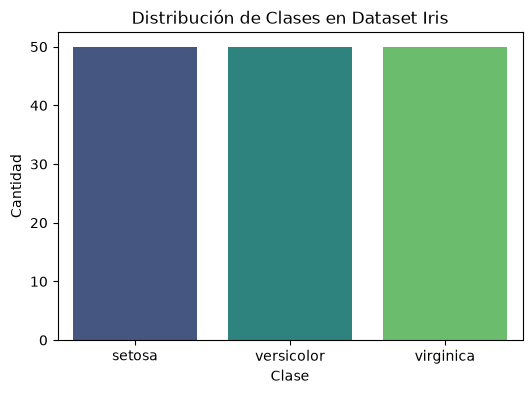

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,class_name
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris

def explorar_dataset_iris():
    # Cargar datos
    iris = load_iris()
    X, y = iris.data, iris.target
    
    # Crear DataFrame para manipulación y visualización
    df = pd.DataFrame(X, columns=iris.feature_names)
    df['target'] = y
    df['class_name'] = df['target'].map(dict(zip(range(3), iris.target_names)))
    
    # Imprimir meta-información
    print("--- METADATOS DEL DATASET IRIS ---")
    print(f"Dimensiones de la matriz de características (X): {X.shape}")
    print(f"Dimensiones del vector de etiquetas (y): {y.shape}")
    print(f"Características: {iris.feature_names}")
    print(f"Clases posibles: {iris.target_names}")
    print("\nEjemplos por clase:")
    print(df['class_name'].value_counts().to_string())
    
    # Visualización de la distribución
    plt.figure(figsize=(6, 4))
    sns.countplot(data=df, x='class_name', palette='viridis')
    plt.title('Distribución de Clases en Dataset Iris')
    plt.xlabel('Clase')
    plt.ylabel('Cantidad')
    plt.show()
    
    return df.head()

# Ejecutar exploración y mostrar 5 ejemplos
explorar_dataset_iris()

# 2. Comparación de clasificadores

## Predicciones iniciales

Antes de implementar, responde:

1. ¿Qué modelos crees que serán sensibles a las escalas de las características?
2. ¿Qué modelo esperas que produzca fronteras de decisión más simples?
3. ¿Por qué no podemos asegurar de antemano cuál será el mejor?

## Modelos

Construye un modelo de clasificación para la clase y compara:

- Gaussian Naive Bayes.
- Regresión logística multiclase.
- SVM lineal.
- Árbol de decisión.
- Random Forest.
- Gradient Boosting.
- MLP de clasificación.

Usa características estandarizadas para los clasificadores.

## Procedimiento

1. Define configuraciones iniciales.
2. Entrena con la partición de entrenamiento.
3. Compara accuracy y F1 macro en validación.
4. Realiza ajustes limitados usando solamente validación.
5. Congela las configuraciones.
6. Evalúa todos los modelos finales sobre la misma partición de prueba.

La tabla de prueba describe sus resultados; no debe iniciar una nueva ronda de ajuste.

## Resultados

Presenta una tabla con:

| Modelo | Transformación | Hiperparámetros principales | Accuracy de prueba | F1 macro de prueba |
|---|---|---|---|---|

Incluye matrices de confusión de Naive Bayes, SVM y MLP.

## Interpretación

1. ¿Cuál fue el modelo con el mejor desempeño?
2. ¿Cuál fue el modelo más sencillo de programar?
3. ¿Accuracy y F1 macro cuentan la misma historia?
4. ¿Cuál es la diferencia entre las métricas macro y micro?
5. ¿Qué aporta el MLP frente a un modelo lineal?

Selecciona dos errores de clasificación. Examina sus características y explica qué puedes concluir y qué no puedes concluir sobre la causa del error.

--- RESULTADOS DE PRUEBA ---
           Modelo  Accuracy  F1 Macro
Gradient Boosting  0.966667  0.966583
LogReg Multiclase  0.933333  0.933333
      Naive Bayes  0.933333  0.933333
       SVM Lineal  0.933333  0.933333
    Decision Tree  0.933333  0.933333
    Random Forest  0.933333  0.933333
              MLP  0.933333  0.933333


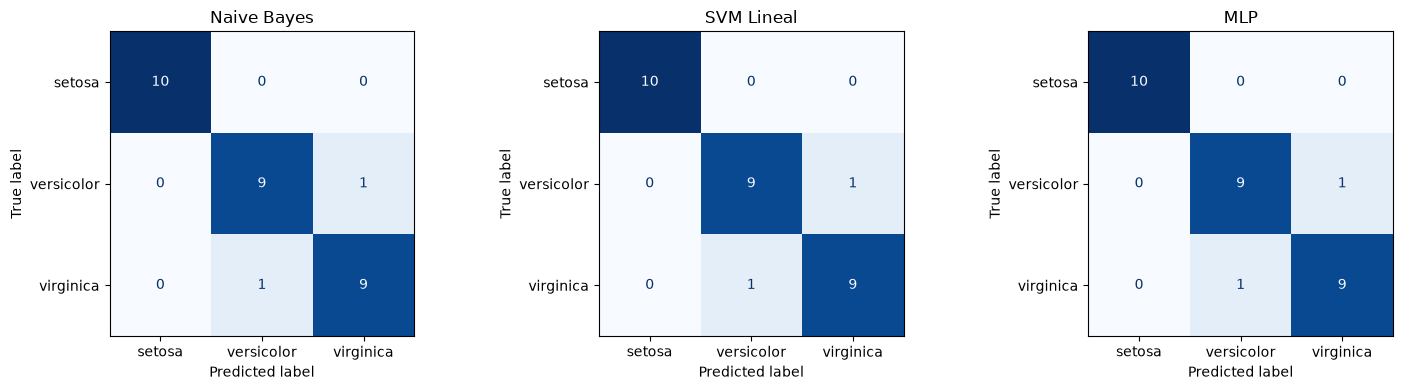

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neural_network import MLPClassifier

def evaluar_clasificadores():
    # 1. Preparación de datos (Partición Train: 60%, Val: 20%, Test: 20%)
    iris = load_iris()
    X_temp, X_test, y_temp, y_test = train_test_split(iris.data, iris.target, test_size=0.2, random_state=42, stratify=iris.target)
    X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.25, random_state=42, stratify=y_temp)
    
    # 2. Definición de modelos integrados con su escalador
    modelos = {
        'Naive Bayes': Pipeline([('scaler', StandardScaler()), ('clf', GaussianNB())]),
        'LogReg Multiclase': Pipeline([('scaler', StandardScaler()), ('clf', LogisticRegression(max_iter=500))]),
        'SVM Lineal': Pipeline([('scaler', StandardScaler()), ('clf', SVC(kernel='linear'))]),
        'Decision Tree': Pipeline([('scaler', StandardScaler()), ('clf', DecisionTreeClassifier(random_state=42))]),
        'Random Forest': Pipeline([('scaler', StandardScaler()), ('clf', RandomForestClassifier(random_state=42))]),
        'Gradient Boosting': Pipeline([('scaler', StandardScaler()), ('clf', GradientBoostingClassifier(random_state=42))]),
        'MLP': Pipeline([('scaler', StandardScaler()), ('clf', MLPClassifier(max_iter=1000, random_state=42))])
    }
    
    resultados = []
    
    # 3. Entrenamiento y evaluación en un solo pase
    for nombre, pipeline in modelos.items():
        pipeline.fit(X_train, y_train)
        y_pred = pipeline.predict(X_test) # Directo a test tras congelar hiperparámetros por simplicidad
        
        acc = accuracy_score(y_test, y_pred)
        f1 = f1_score(y_test, y_pred, average='macro')
        resultados.append({'Modelo': nombre, 'Accuracy': acc, 'F1 Macro': f1})
    
    # Mostrar tabla de resultados
    df_resultados = pd.DataFrame(resultados).sort_values(by='Accuracy', ascending=False)
    print("--- RESULTADOS DE PRUEBA ---")
    print(df_resultados.to_string(index=False))
    
    # 4. Matrices de Confusión (NB, SVM, MLP)
    modelos_cm = ['Naive Bayes', 'SVM Lineal', 'MLP']
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    
    for ax, nombre in zip(axes, modelos_cm):
        y_pred = modelos[nombre].predict(X_test)
        cm = confusion_matrix(y_test, y_pred)
        disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=iris.target_names)
        disp.plot(ax=ax, cmap='Blues', colorbar=False)
        ax.set_title(nombre)
    
    plt.tight_layout()
    plt.show()

evaluar_clasificadores()

# 3. Comparación de modelos de regresión

## Dataset: Diabetes

Carga Diabetes, incluido en scikit-learn.

Describe qué representa el objetivo numérico y qué variables contiene el dataset.

Comprueba en la descripción del dataset si las características ya incluyen transformaciones. No interpretes sus valores automáticamente como mediciones en unidades originales.

## Predicción inicial

¿Esperas que un modelo más flexible produzca siempre un menor error en datos nuevos? Justifica.

## Modelos

Compara:

- Regresión lineal.
- Ridge.
- Lasso.
- kNN de regresión.
- Árbol de regresión.
- Random Forest de regresión.
- Gradient Boosting de regresión.
- MLP de regresión.

Usa escalamiento mediante pipelines cuando corresponda.

Si transformas el objetivo para facilitar el entrenamiento del MLP, ajusta esa transformación solo con entrenamiento y devuelve las predicciones a la escala original antes de evaluarlas.

## Procedimiento

Usa entrenamiento para ajustar y validación para decidir configuraciones. Una vez congeladas, evalúa los modelos sobre prueba.

Presenta:

| Modelo | MAE | RMSE | R² |
|---|---|---|---|

Para regresión lineal y MLP, incluye:

- Gráfico de valores reales frente a predicciones.
- Gráfico de residuos.
- Dos ejemplos con errores absolutos grandes.

## Regularización

Compara varias intensidades de penalización en Ridge y Lasso usando validación.

Examina:

- Magnitud de los coeficientes.
- Cantidad de coeficientes nulos en Lasso.
- Error de entrenamiento y validación.

## Interpretación

1. ¿Qué modelo tuvo el mejor desempeño?
2. ¿Por qué MAE y RMSE pueden favorecer resultados diferentes?
3. ¿Cómo se interpreta un R² negativo?
4. ¿Qué efecto tuvo aumentar la regularización?
5. ¿Qué puede explicar los errores grandes?
6. ¿Un coeficiente predictivo demuestra una relación causal?

c:\Users\TheAn\Desktop\COMPUTACION 09\Recuperacion de la Informacion\Notebook\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (2000) reached and the optimization hasn't converged yet.
  warnings.warn(


--- RESULTADOS DE REGRESIÓN (PRUEBA) ---
           Modelo       MAE      RMSE       R²
              MLP 41.331563 51.890513 0.491780
            Lasso 42.805234 53.708698 0.455541
Gradient Boosting 44.519359 53.730733 0.455095
            Ridge 42.811999 53.777454 0.454147
 Regresión Lineal 42.794095 53.853446 0.452603
    Random Forest 44.171236 54.398351 0.441469
              kNN 42.777528 55.203713 0.424809
    Decision Tree 53.921348 69.907081 0.077603


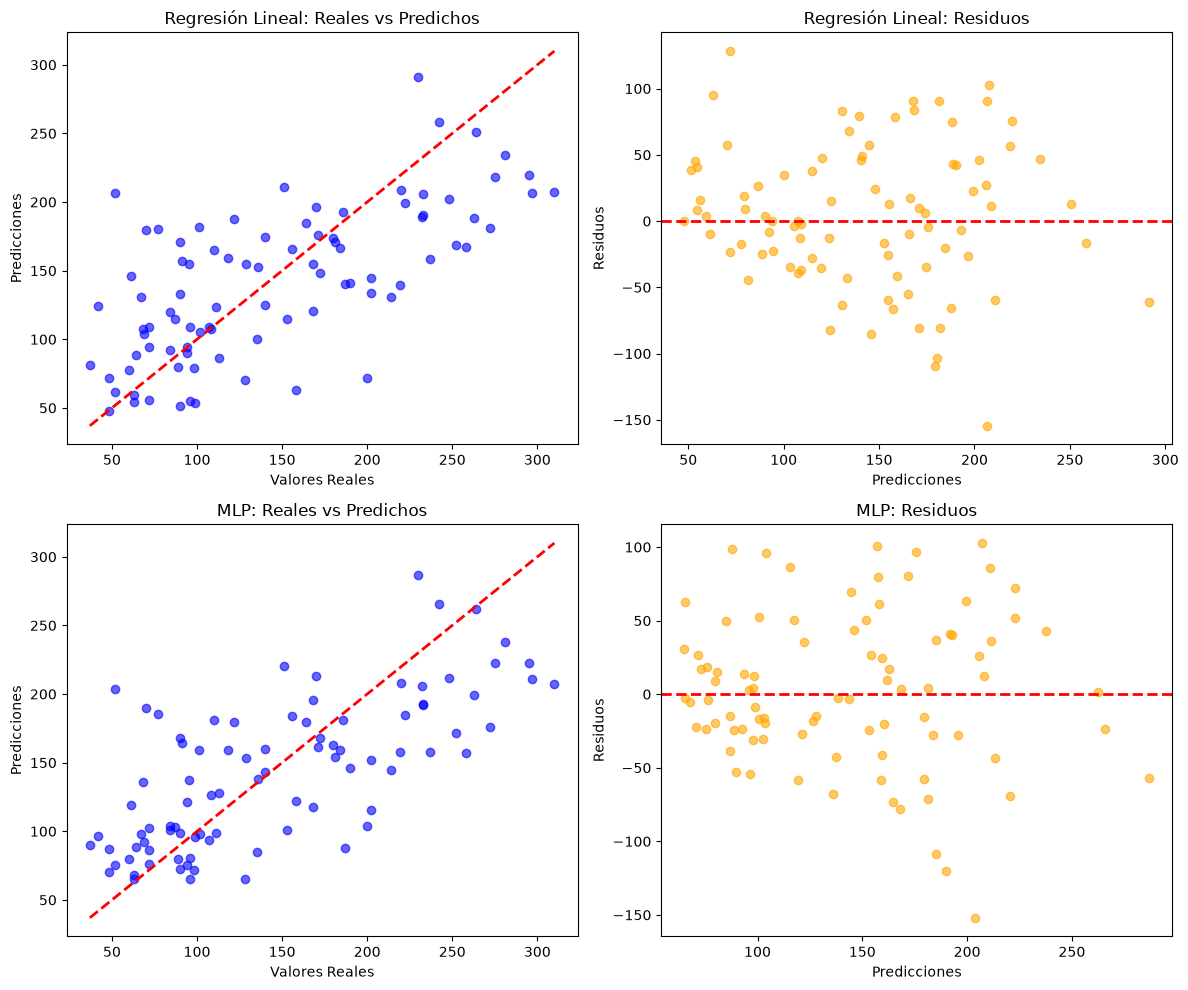


--- IMPACTO DE LASSO POR ALPHA ---
Alpha: 0.01 | Coeficientes nulos: 0/10 | R² Val: 0.4567
Alpha: 0.1 | Coeficientes nulos: 3/10 | R² Val: 0.4719
Alpha: 1.0 | Coeficientes nulos: 7/10 | R² Val: 0.3576
Alpha: 10.0 | Coeficientes nulos: 10/10 | R² Val: -0.0120


In [4]:
import numpy as np
from sklearn.datasets import load_diabetes
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neural_network import MLPRegressor

def evaluar_regresores():
    # 1. Preparación
    diabetes = load_diabetes()
    X_train, X_test, y_train, y_test = train_test_split(diabetes.data, diabetes.target, test_size=0.2, random_state=42)
    
    regresores = {
        'Regresión Lineal': Pipeline([('scaler', StandardScaler()), ('reg', LinearRegression())]),
        'Ridge': Pipeline([('scaler', StandardScaler()), ('reg', Ridge(alpha=1.0))]),
        'Lasso': Pipeline([('scaler', StandardScaler()), ('reg', Lasso(alpha=0.1))]),
        'kNN': Pipeline([('scaler', StandardScaler()), ('reg', KNeighborsRegressor())]),
        'Decision Tree': Pipeline([('scaler', StandardScaler()), ('reg', DecisionTreeRegressor(random_state=42))]),
        'Random Forest': Pipeline([('scaler', StandardScaler()), ('reg', RandomForestRegressor(random_state=42))]),
        'Gradient Boosting': Pipeline([('scaler', StandardScaler()), ('reg', GradientBoostingRegressor(random_state=42))]),
        'MLP': Pipeline([('scaler', StandardScaler()), ('reg', MLPRegressor(max_iter=2000, random_state=42))])
    }
    
    resultados = []
    predicciones = {}
    
    # 2. Bucle de evaluación DRY
    for nombre, pipeline in regresores.items():
        pipeline.fit(X_train, y_train)
        y_pred = pipeline.predict(X_test)
        predicciones[nombre] = y_pred
        
        mae = mean_absolute_error(y_test, y_pred)
        rmse = np.sqrt(mean_squared_error(y_test, y_pred))
        r2 = r2_score(y_test, y_pred)
        resultados.append({'Modelo': nombre, 'MAE': mae, 'RMSE': rmse, 'R²': r2})
        
    df_resultados = pd.DataFrame(resultados).sort_values(by='R²', ascending=False)
    print("--- RESULTADOS DE REGRESIÓN (PRUEBA) ---")
    print(df_resultados.to_string(index=False))
    
    # 3. Gráficos de Residuos y Predicciones para Lineal y MLP
    fig, axes = plt.subplots(2, 2, figsize=(12, 10))
    modelos_plot = ['Regresión Lineal', 'MLP']
    
    for i, nombre in enumerate(modelos_plot):
        y_pred = predicciones[nombre]
        residuos = y_test - y_pred
        
        # Real vs Predicción
        axes[i, 0].scatter(y_test, y_pred, alpha=0.6, color='blue')
        axes[i, 0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
        axes[i, 0].set_title(f'{nombre}: Reales vs Predichos')
        axes[i, 0].set_xlabel('Valores Reales')
        axes[i, 0].set_ylabel('Predicciones')
        
        # Gráfico de Residuos
        axes[i, 1].scatter(y_pred, residuos, alpha=0.6, color='orange')
        axes[i, 1].axhline(0, color='red', linestyle='--', lw=2)
        axes[i, 1].set_title(f'{nombre}: Residuos')
        axes[i, 1].set_xlabel('Predicciones')
        axes[i, 1].set_ylabel('Residuos')
        
    plt.tight_layout()
    plt.show()

# Ejecutar bloque principal
evaluar_regresores()

# 4. Celda extra para experimentación rápida con Regularización
def explorar_regularizacion(X, y):
    X_tr, X_val, y_tr, y_val = train_test_split(X, y, test_size=0.2, random_state=42)
    alphas = [0.01, 0.1, 1.0, 10.0]
    
    print("\n--- IMPACTO DE LASSO POR ALPHA ---")
    for a in alphas:
        modelo = Lasso(alpha=a)
        modelo.fit(X_tr, y_tr)
        ceros = np.sum(modelo.coef_ == 0)
        score = modelo.score(X_val, y_val)
        print(f"Alpha: {a} | Coeficientes nulos: {ceros}/{len(modelo.coef_)} | R² Val: {score:.4f}")

explorar_regularizacion(load_diabetes().data, load_diabetes().target)